In [ ]:
## Script for analysis of neuroimaging data from Representations of Sentence Meaning in the Brain
# Run with python 3.10 fMRI env
# James Fodor 2024

# load libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools
import pandas as pd
import os

# load custom functions from library
import sentence_embeds_processing as sep
import voxels_processing as vp
   
# set display options
np.set_printoptions(precision=3, threshold=6000, linewidth=220, suppress=True, floatmode='fixed')
pd.set_option('display.max_columns', None)
sns.set()

In [21]:
import importlib
importlib.reload(vp)

<module 'voxels_processing' from 'd:\\Code\\Python\\2023_07_Sentence_Meaning_in_the_Brain\\voxels_processing.py'>

### Load fMRI similarity data

In [10]:
## Load sentences and subjects data

# Load metadata for experimental subjects
subject_data_raw = np.loadtxt('Fodor2024-subject_data.txt', delimiter=';', dtype='str', encoding='utf-8', skiprows=1)
subject_data_dict = {sbj_data[0]:(sbj_data[1:]).astype('float') for sbj_data in subject_data_raw}
all_subjects = list(subject_data_dict.keys())
noneng_subjects = ['06','07','14','16','21','23','31','34','36','38','39','40','43'] # participant ID from non-English majority countries
eng_subjects = [idx for idx in all_subjects if idx not in noneng_subjects]
print('Loaded '+str(len(all_subjects))+' experimental subjects')

# set key parameters for loading data
dataset_name = 'Fodor2024-final108' # dataset name
repeats = [0,1,2,3] # stimulus repeats to include in analysis
num_sets = 6 # the number of sets of related sentences
timing = 'mid' # start, end, mid
corr_method = 'spearman'  # spearman or pearson correlation
similarity_type = 'diemsim'  # options: 'cosine' or 'diemsim' or 'all'
stability_level = 0.07 # voxel stability threshold
controls_type = 2 # 1=sentence lengths only, 2=sentence lengths and minimum lengths, 3=visual cortex

# load sentences set
all_sentences = np.loadtxt(dataset_name+'_sentences.txt', delimiter=';', dtype='str', encoding='utf-8')
all_sentences_indices = np.arange(len(all_sentences))
sent_pairs_all = list(itertools.combinations(all_sentences_indices, 2))
sent_pair_ids_all = np.arange(len(sent_pairs_all))
num_stimuli = all_sentences_indices.shape[0]
sent_pair_ids_diag = vp.get_pairs_in_diag(all_sentences_indices, num_sets)
num_repeats = len(repeats)

# Load sentence pair types
sentpair_types_list = np.loadtxt('Fodor2024-final108_types-brief.txt', dtype=int)
sent_pair_ids_modsub = [idx for idx,type in enumerate(sentpair_types_list) if type==6]
sent_pair_ids_diffs = [idx for idx,type in enumerate(sentpair_types_list) if type==5]
sent_pair_ids_swaps = [idx for idx,type in enumerate(sentpair_types_list) if type==4]
sent_pair_ids_subs = [idx for idx,type in enumerate(sentpair_types_list) if type==3]
sent_pair_ids_mods = [idx for idx,type in enumerate(sentpair_types_list) if type==2]
sent_pair_ids_sames = [idx for idx,type in enumerate(sentpair_types_list) if type==1]
sent_pair_ids_key = [idx for idx,type in enumerate(sentpair_types_list) if type in [2,3,4,5]]

# print summary
print('Stimuli:',num_stimuli)
print('Timing:',timing)
print('Num repeats:',num_repeats)
print('All pairs:',len(sent_pair_ids_all))
print('Diag pairs:',len(sent_pair_ids_diag))

Loaded 39 experimental subjects
Stimuli: 108
Timing: mid
Num repeats: 4
All pairs: 5778
Diag pairs: 918


In [3]:
## Set key parameters for computing similarities

# Specify voxel averaging and voxel subset options (for looping over later)
av_types = ['mean']
pair_subsets = ['all','diag']
other_parms = []
for av_type in av_types:
    for pair in pair_subsets:
        other_parms.append(av_type+'_'+pair)

# Collect all subsets of voxels to use for computation of similarities
voxel_sets_to_plot = {}
for av_type in av_types:
    all_voxel_sets = os.listdir('Data-fmri/similarities/'+timing+'_3s/sub-05-sims/')
    voxel_sets_to_plot[av_type] = [i[25:-4] for i in all_voxel_sets if i.startswith('sub-05_similarities-'+av_type+'-') and i.endswith('norm.txt')]

# Collect subsets of sentences pairs for similarity analyses
similarity_subsets = {'all':sent_pair_ids_all, 'diag':sent_pair_ids_diag}
print('Voxel sets:',len(voxel_sets_to_plot['mean']))

Voxel sets: 122


In [4]:
## Load model similarities and fmri similarities
 
# Load model similarities
model_sims_base = 'Data-models/similarities/'
model_sims_storage = vp.load_model_sims(model_sims_base, dataset_name, normalisation=True, sim_type=similarity_type)
model_sims_storage['visual_sims'] = np.loadtxt('Data-analysis\\Fodor2024-final108_'+timing+'_visual_sims_mean.txt', dtype=float)
model_sims_storage['transformers_norml_'+similarity_type] = np.random.rand(len(sent_pair_ids_all)) # blank entry for averaged transformers so they are in the dictionary

print('Loaded '+str(len(model_sims_storage.keys()))+' computational models')

# Load neuro similarities
fmri_sims_base = 'Data-fmri/similarities/'
neuro_sims_storage = dict(zip(all_subjects, [{type:{} for type in av_types} for x in all_subjects])) # blank empty dictionary for storage
for sbj_id in all_subjects:
    for av_type in av_types:
        for voxel_set in voxel_sets_to_plot[av_type]:
            neuro_sims_path = fmri_sims_base+timing+'_3s/'+'sub-'+sbj_id+'-sims/'
            with open(neuro_sims_path+'sub-'+sbj_id+'_similarities-'+av_type+'-'+voxel_set+'.txt', encoding='latin-1') as file:
                neuro_sims_storage[sbj_id][av_type][voxel_set] = np.array([float(line.rstrip('\n')) for line in file])
                              
# Specify which experimental subjects to include
accuracy_threshold = 0.73 #0.70, 0.80
movement_threshold = 4.01 #4.01, 2.01
included_subjects = [sbj_id for sbj_id in all_subjects if subject_data_dict[sbj_id][0] >= accuracy_threshold and subject_data_dict[sbj_id][1] <= movement_threshold]
print('Including '+str(len(included_subjects))+' experimental subjects')

# Compute the average similarities over participants and store in dictionary
mean_subj_sims = {type:{} for type in av_types}
for av_type in av_types:
    for voxel_set in voxel_sets_to_plot[av_type]:
        voxelset_sims = [neuro_sims_storage[sbj_id][av_type][voxel_set] for sbj_id in included_subjects]
        mean_subj_sims[av_type][voxel_set] = np.mean(voxelset_sims, axis=0)
neuro_sims_storage['mean'] = mean_subj_sims

# Load control variables
control_vars = vp.get_control_vars(controls_type, model_sims_storage)
print('Using '+str(controls_type)+' control variables')

Loaded 104 computational models
Including 30 experimental subjects
Using 2 control variables


### Compute ROI raw correlations

Number regions: 7
Matrix size: (7, 7)
Raw correlations
Including 30 participants
Stability: 0.07
Timing: mid


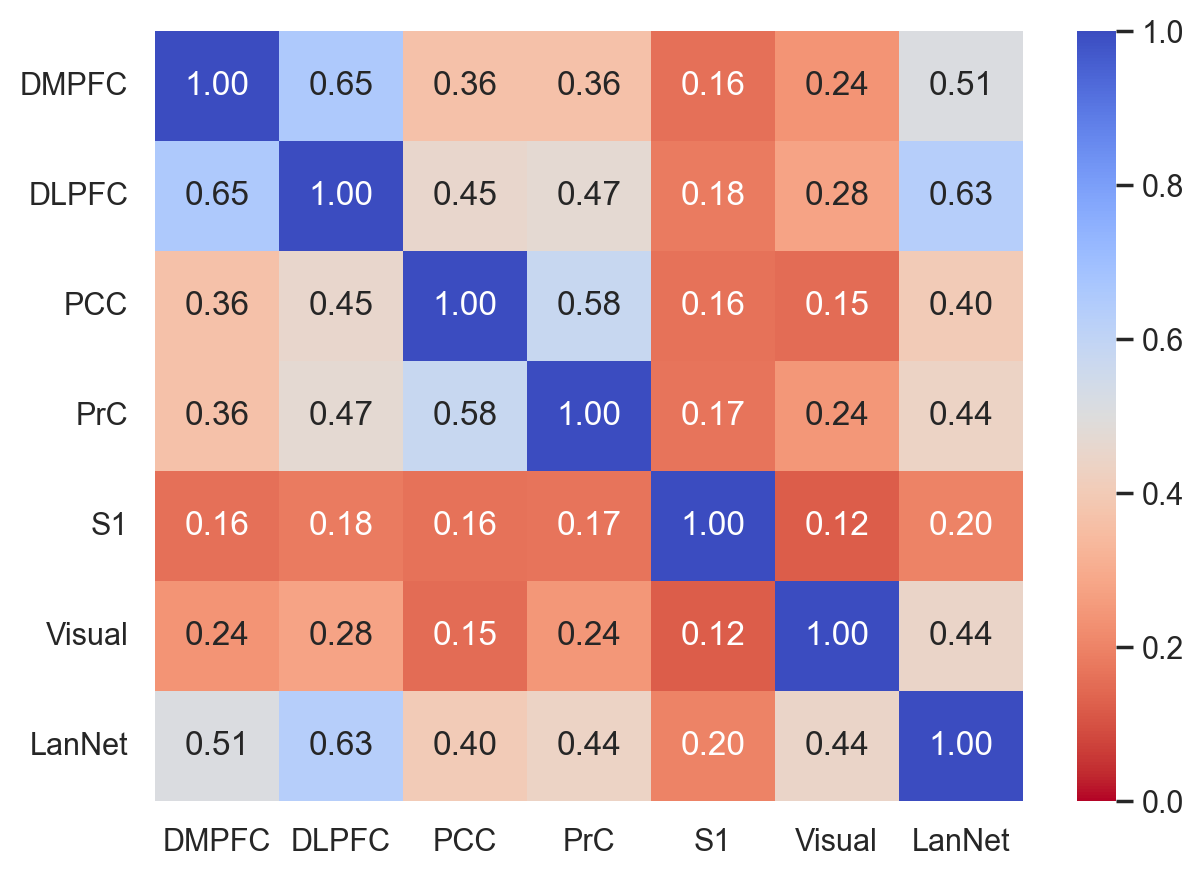

In [18]:
# Specify Glasser Atlas ROIs
stability_str = str(stability_level)
ROIs_dict = {'voxels_lanROIs': ['LanROI-AntTemp-stable-'+stability_str+'-norm','LanROI-PostTemp-stable-'+stability_str+'-norm','LanROI-AG-stable-'+stability_str+'-norm',
                                'LanROI-MFG-stable-'+stability_str+'-norm','LanROI-IFG-stable-'+stability_str+'-norm','LanROI-IFGorb-stable-'+stability_str+'-norm'], # for lanROI comparison
             'voxels_cortexROIs': ['Glasser-dorsomedial_PFC-stable-'+stability_str+'-norm','Glasser-dorsolateral_PFC-stable-'+stability_str+'-norm',
                                   'Glasser-posterior_cingulate-stable-'+stability_str+'-norm','Glasser-precuneus-stable-'+stability_str+'-norm',
                                   'Glasser-primary_sensory-stable-'+stability_str+'-norm','Glasser-primary_visual-stable-'+stability_str+'-norm','LanROI-all-stable-'+stability_str+'-norm']}
names_dict = {'voxels_lanROIs': ['AntTemp','PostTemp','AG','MFG','IFG','IFGorb'],
             'voxels_cortexROIs': ['DMPFC', 'DLPFC', 'PCC', 'PrC', 'S1','Visual','LanNet']}

# Select regions
voxel_set = 'voxels_cortexROIs'
print('Number regions:',len(ROIs_dict[voxel_set]))

# Compute correlation matrix over ROIs
subset = sent_pair_ids_all # sent_pair_ids_diag, sent_pair_ids_all

correlation_matrices = []
for sub_id in included_subjects:
    neuro_sims_ROI = []
    for ROI in ROIs_dict[voxel_set]:
        neuro_sims_ROI.append(neuro_sims_storage[sub_id]['mean'][ROI][subset])
    correlation_matrices.append(np.corrcoef(neuro_sims_ROI))
    
final_corr_matrix = np.mean(correlation_matrices,axis=0)
print('Matrix size:',final_corr_matrix.shape)

# Print details
print('Raw correlations')
print('Including',len(included_subjects),'participants')
print('Stability:',stability_level)
print('Timing:',timing)

# Seaborn heatmap plot
fig, ax = plt.subplots(figsize=(7,5), facecolor='white', dpi=200)
sns.heatmap(final_corr_matrix, annot=True, fmt='.2f', cmap='coolwarm_r', cbar=True, vmin=0, vmax=1, xticklabels=names_dict[voxel_set], yticklabels=names_dict[voxel_set])
plt.xticks(rotation=0) 
plt.yticks(rotation=0) 
plt.show()

### Compute ROI partial correlations

Matrix size: (7, 7)
Partial correlations
Including 30 participants
Stability: 0.07
Control type: 2
Timing: mid


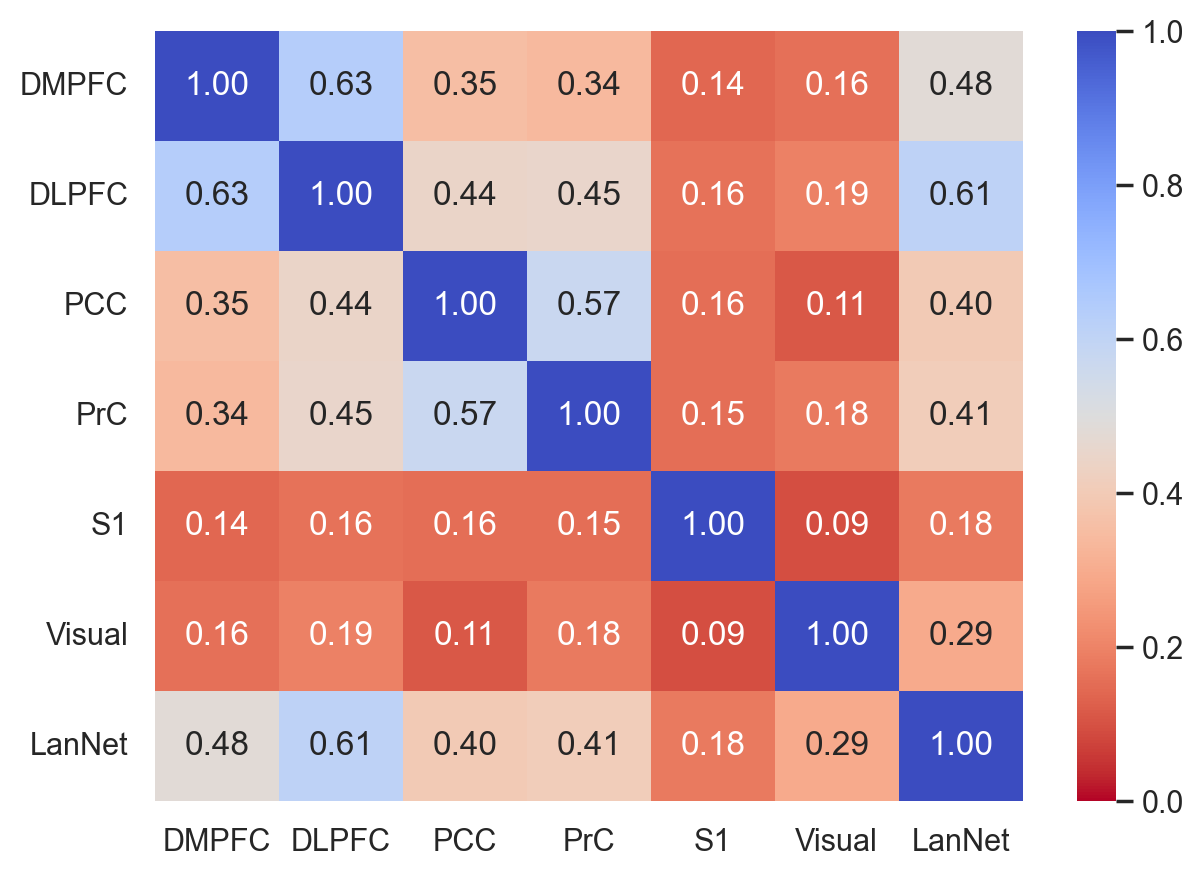

In [23]:
# Choose controls to use
graph_control=2
control_vars = vp.get_control_vars(graph_control, model_sims_storage)

# Compute similarities while regressing out a control variable
stable_type = 'stable-'+str(stability_level)
neuro_sims_storage_regress = {}
for sub_id in all_subjects:
    single_sub_dict = {ROI_name:neuro_sims_storage[sub_id]['mean'][ROI_name] for ROI_name in ROIs_dict[voxel_set]}
    resids, partial_corr = vp.regress_out_controls(single_sub_dict, control_vars)
    neuro_sims_storage_regress[sub_id] = resids
    # np.savetxt(file_paths_dict['Fodor2024-final108_neuro-sims-'+timing]+'sub-'+sub_id+'-sims\\'+'sub-'+sub_id+'_similarities-mean-Glasser-cortex_novis-ctrlvis-'+stable_type+'-norm.txt', resids[sub_id], fmt='%.4f')
    
# Compute the average similarities over participants and store in dictionary
mean_subj_sims_regress = {}
for ROI in ROIs_dict[voxel_set]:
    voxelset_sims = [neuro_sims_storage_regress[sbj_id][ROI] for sbj_id in included_subjects]
    mean_subj_sims_regress[ROI] = np.mean(voxelset_sims, axis=0)
neuro_sims_storage_regress['mean'] = mean_subj_sims_regress

# Compute correlation matrix over ROIs
subset = sent_pair_ids_all # sent_pair_ids_diag, sent_pair_ids_all

correlation_matrices_regress = []
for sub_id in included_subjects:
    neuro_sims_ROI = []
    for ROI in ROIs_dict[voxel_set]:
        neuro_sims_ROI.append(neuro_sims_storage_regress[sub_id][ROI][subset])
    correlation_matrices_regress.append(np.corrcoef(neuro_sims_ROI))

final_corr_matrix_regress = np.mean(correlation_matrices_regress,axis=0)
print('Matrix size:',final_corr_matrix_regress.shape)

# Print details
print('Partial correlations')
print('Including',len(included_subjects),'participants')
print('Stability:',stability_level)
print('Control type:',graph_control)
print('Timing:',timing)

# Seaborn heatmap plot
fig, ax = plt.subplots(figsize=(7,5), facecolor='white', dpi=200)
sns.heatmap(final_corr_matrix_regress, annot=True, fmt='.2f', cmap='coolwarm_r', vmin=0, vmax=1, cbar=True, xticklabels=names_dict[voxel_set], yticklabels=names_dict[voxel_set])
plt.xticks(rotation=0) 
plt.yticks(rotation=0) 
plt.show()

### Additional code for RSA-searchlight

In [13]:
## Regress out control variables from model similarities (for use in RSA-searchlight)

# only turn on when needed
if (0): 
        
    # Save sims for each model
    for model_name in model_sims_storage.keys():
        
        # Get regression results
        resids, partial_corr = vp.regress_out_controls(model_sims_storage, control_vars)

        # Save and print results
        print(model_name,'Partial-corr:',partial_corr[model_name])
        partial_cor_filename = 'Fodor2024-final108_neuro_'+model_name+'_reg-min&diff_similarities.txt'
        # np.savetxt(partial_cor_filename, resids[model_name], fmt='%.4f')
        
    # Save group-averaged neuro sims
    for voxel_set in voxel_sets_to_plot:
        
        # Get regression results
        resids, partial_corr = vp.regress_out_controls(neuro_sims_storage['mean']['mean'], control_vars)
        
        # Save and print results
        print(voxel_set,'Partial-corr:',partial_corr[voxel_set])
        np.savetxt('Fodor2024-final108_neuro_fmri_av-'+voxel_set+'_reg-min&diff_similarities.txt', resids[voxel_set], fmt='%.4f')
    
    # Save control variables
    np.savetxt('Fodor2024-final108_lengthdiff_similarities.txt', sent_length_diffs_vector, fmt='%.4f')
    np.savetxt('Fodor2024-final108_minlength_similarities.txt', sent_length_mins_vector, fmt='%.4f')